# 1.从全连接层到卷积
* 多层感知机非常适合处理**表格**数据，其中行对应样本，列对应特征。对于表格数据，我们寻找的模式可能涉及特征之间的交互，但是我们不能**预先假设任何与特征交互有关的先验结构**
* 在处理图像数据时，我们如果直接展平，会丢失很多图像的空间结构信息，而且参数量容易爆炸

## 等变性
物体的识别结果，和物体出现在图像中的位置无关。物体向左、向右、向上、向下平移，模型依然能正确认出这是什么物体。

1. *平移等变性*（translation equivariance）：不管检测对象出现在图像中的哪个位置，神经网络的前面几层应该**对相同的图像区域具有相似的反应**，即为“平移不变性”。
2. *局部性*（locality）：神经网络的前面几层应该**只探索输入图像中的局部区域**，而**不过度在意图像中相隔较远区域的关系**，这就是“局部性”原则。最终，可以聚合这些局部特征，以在整个图像级别进行预测。

## 多层感知机的局限性

这里可以理解为，我们在**不展平二维图像的情况下进行前向传播**，每一个位置相当于一个样本，对应的特征维度是整个二维矩阵的元素数量，相当于每一个位置都有一个对应的权重矩阵，所以整个二维图像的权重矩阵是四阶的，前两维表示位置，后两维表示独立的权重矩阵

首先，多层感知机的输入是二维图像$\mathbf{X}$，其隐藏表示$\mathbf{H}$在数学上是一个矩阵，在代码中表示为二维张量。
其中$\mathbf{X}$和$\mathbf{H}$具有相同的形状。
为了方便理解，我们可以认为，无论是输入还是隐藏表示都拥有空间结构。

使用$[\mathbf{X}]_{i, j}$和$[\mathbf{H}]_{i, j}$分别表示输入图像和隐藏表示中位置（$i$,$j$）处的像素。
为了使每个隐藏神经元都能接收到每个输入像素的信息，我们将参数从权重矩阵（如同我们先前在多层感知机中所做的那样）替换为四阶权重张量$\mathsf{W}$。这里的**四阶权重相当于每一个位置都有独立的一套权重**。假设$\mathbf{U}$包含偏置参数，我们可以将全连接层形式化地表示为

$$\begin{aligned} \left[\mathbf{H}\right]_{i, j} &= [\mathbf{U}]_{i, j} + \sum_k \sum_l[\mathsf{W}]_{i, j, k, l}  [\mathbf{X}]_{k, l}\\ &=  [\mathbf{U}]_{i, j} +
\sum_a \sum_b [\mathsf{V}]_{i, j, a, b}  [\mathbf{X}]_{i+a, j+b}.\end{aligned}$$

这个坐标变换改写为了**邻域形式**，a，b代表相对偏移量

其中，从$\mathsf{W}$到$\mathsf{V}$的转换只是形式上的转换，因为在这两个四阶张量的元素之间存在一一对应的关系。
我们只需重新索引下标$(k, l)$，使$k = i+a$、$l = j+b$，由此可得$[\mathsf{V}]_{i, j, a, b} = [\mathsf{W}]_{i, j, i+a, j+b}$。
索引$a$和$b$通过在正偏移和负偏移之间移动覆盖了整个图像。
对于隐藏表示中任意给定位置（$i$,$j$）处的像素值$[\mathbf{H}]_{i, j}$，可以通过在$x$中以$(i, j)$为中心对像素进行加权求和得到，加权使用的权重为$[\mathsf{V}]_{i, j, a, b}$。

### 平移等变性
这意味着检测对象在输入$\mathbf{X}$中的平移，应该仅导致隐藏表示$\mathbf{H}$中的平移。也就是说，$\mathsf{V}$和$\mathbf{U}$实际上不依赖于$(i, j)$的值，即$[\mathsf{V}]_{i, j, a, b} = [\mathbf{V}]_{a, b}$。并且$\mathbf{U}$是一个常数，比如$u$。因此，我们可以简化$\mathbf{H}$定义为：
$$[\mathbf{H}]_{i, j} = u + \sum_a\sum_b [\mathbf{V}]_{a, b} [\mathbf{X}]_{i+a, j+b}.$$
这就是*卷积*（convolution）。我们是在使用系数$[\mathbf{V}]_{a, b}$对位置$(i, j)$附近的像素$(i+a, j+b)$进行加权得到$[\mathbf{H}]_{i, j}$。
注意，$[\mathbf{V}]_{a, b}$的系数比$[\mathsf{V}]_{i, j, a, b}$少很多，因为**前者不再依赖于图像中的位置**。这就是显著的进步！

### 局部性
如上所述，为了收集用来训练参数$[\mathbf{H}]_{i, j}$的相关信息，我们不应偏离到距$(i, j)$很远的地方。这意味着在$|a|> \Delta$或$|b| > \Delta$的范围之外，我们可以设置$[\mathbf{V}]_{a, b} = 0$。因此，我们可以将$[\mathbf{H}]_{i, j}$重写为

$$[\mathbf{H}]_{i, j} = u + \sum_{a = -\Delta}^{\Delta} \sum_{b = -\Delta}^{\Delta} [\mathbf{V}]_{a, b}  [\mathbf{X}]_{i+a, j+b}.$$
这就是一个*卷积层*，卷积神经网络是包含卷积层的一类特殊神经网络。在深度学习研究社区中，$\mathbf{V}$被称为*卷积核*（convolution kernel）或者*滤波器*（filter），亦或简单地称之为该卷积层的*权重*，通常该权重是可学习的参数。
当图像处理的局部区域很小时，卷积神经网络与多层感知机的训练差异可能是巨大的：以前，多层感知机可能需要数十亿个参数来表示网络中的一层，而现在卷积神经网络通常只需要几百个参数，而且不需要改变输入或隐藏表示的维数。

参数大幅减少的代价是，我们的特征现在是平移不变的，并且当确定每个隐藏活性值时，每一层只包含局部的信息。
以上所有的权重学习都将依赖于**归纳偏置**。

归纳偏置表示**模型架构预先内置的先验假设，是对目标问题函数形式施加的约束**，可以理解为**在还没看见训练数据之前，我们就告诉模型 “我们认为数据大概长什么样”**
比如现在的卷积层有两条归纳偏置：
* **局部性假设**：图像中，一个位置的输出只依赖邻近像素，远距离像素关联性弱
* **权重共享（平移等变性）假设**：相同视觉模式（纹理，边缘）在图像中任意位置表现形式一样

当任务是**自然图像识别**时，比较符合

当任务是**坐标敏感任务**这种全局远距离依赖或者不满足平移不变性时，不符合

当这种偏置与现实相符时，我们就能得到样本有效的模型，并且这些模型能很好地泛化到未知数据中。
但如果这偏置与现实不符时，比如当图像不满足平移不变时，我们的模型可能难以拟合我们的训练数据。

## 卷积
数学上的卷积和我们实际做的卷积有点不同，我们实际做的“卷积”是**互相关**（Cross-Correlation）

在数学中，两个函数（比如$f, g: \mathbb{R}^d \to \mathbb{R}$）之间的“卷积”被定义为

$$(f * g)(\mathbf{x}) = \int f(\mathbf{z}) g(\mathbf{x}-\mathbf{z}) d\mathbf{z}.$$

也就是说，卷积是当把一个函数“翻转”并移位$\mathbf{x}$时，测量$f$和$g$之间的重叠。
当为离散对象时，积分就变成求和。例如，对于由索引为$\mathbb{Z}$的、平方可和的、无限维向量集合中抽取的向量，我们得到以下定义：

$$(f * g)(i) = \sum_a f(a) g(i-a).$$

对于二维张量，则为$f$的索引$(a, b)$和$g$的索引$(i-a, j-b)$上的对应加和：

$$(f * g)(i, j) = \sum_a\sum_b f(a, b) g(i-a, j-b).$$
而我们实际上经常采用**互相关**运算来代替卷积运算，卷积核不翻转，省去一部分计算  

## 通道

权重张量维度：$\boldsymbol{[\text{核高偏移},\text{核宽偏移},\text{输入通道数},\text{输出通道数}]}$

**灰度单通道图像（二维输入）**

输入$\mathbf{X}[i,j]$，卷积核仅需要二维：$K[a,b]$。

含义：邻域内每个位置对应一个权重。

**RGB 三通道图像（三维输入，输入通道 c 出现）**

输入$\mathsf{X}[i,j,c]$，每个空间位置有 3 个数值（R/G/B）。

想要计算输出一点的值，**每个输入通道都要有独立权重**，此时核变成三维：$V[a,b,c]$。

**想要同时输出多张特征图（新增输出通道 d）**

我们不只想输出 1 张特征图，希望同时生成多张不同特征图（一张检测边缘、一张检测纹理……）。

每一张输出特征图，都需要一套独立的三维卷积核。

于是我们增加第 4 个维度$\boldsymbol{d}$区分不同输出通道：

$\boldsymbol{V[a,b,c,d]}$：生成第d张输出特征图时，在偏移$(a,b)$、输入通道c位置使用的权重。

$$[\mathsf{H}]_{i,j,d} = \sum_{a = -\Delta}^{\Delta} \sum_{b = -\Delta}^{\Delta} \sum_c [\mathsf{V}]_{a, b, c, d} [\mathsf{X}]_{i+a, j+b, c},$$

## 音频卷积层
音频（波形）：一维时序张量 $\boldsymbol{X}[t,c]$

- t：时间步（对应图像空间坐标）
- c：通道（单声道 / 立体声，对应 RGB 通道）

音频使用 **一维卷积 Conv1d**，运算形式为一维互相关：

$$[\boldsymbol{H}]_{t,d} = \sum_{a=-\Delta}^{\Delta}\sum_c [\mathsf{V}]_{a,c,d} [\boldsymbol{X}]_{t+a,c}$$
### 图像 CNN 逻辑

图像（高度 × 宽度 × 通道）→ Conv2d（滑动二维窗口，提取空间局部特征）→ 池化 → 输出特征图

### 音频一维 CNN 逻辑

音频波形（时间步 × 通道）→ **Conv1d（滑动一维时序窗口）** → 时序池化 → 时序特征序列

- 卷积窗口长度 = 感受野，对应一段连续时间内的音频采样点；
- 卷积核沿着**时间轴滑动**，捕捉局部声学模式（音调、短时频谱包络、爆破音等）；
- 权重共享：**相同声学模式无论出现在音频哪个时间点，都可以被检测器识别**（时序等变性，类比图像平移等变性）。

## 文本
**卷积层可以用于文本，但相比图像，适配性更有限；在特定场景有效，不是文本最优方案（现在主流是 Transformer）。典型代表：TextCNN。**

### 1、先建立类比

图像：二维网格，局部相邻像素天然强相关；CNN 依靠**局部感受野 + 权重共享 + 空间等变性**提取局部视觉模式。

文本：序列$\boldsymbol{x}_1,\boldsymbol{x}_2,\dots,\boldsymbol{x}_T$，每个元素是词嵌入向量。

文本使用**一维卷积 Conv1d**：

$[\boldsymbol{H}]_{t,d}=\sum_{a}\sum_c V_{a,c,d}\boldsymbol{X}_{t+a,c}$

卷积沿**序列方向滑动窗口**，捕捉连续若干词语的组合特征（n 元语法 n-gram）。

### 2、适合文本的理由（优势）

1. **捕捉局部连续短语特征**

   窗口大小为k的一维卷积，可以建模连续k个单词的语义组合（类似 2-gram、3-gram 短语）。

   例子：`not good`、`very beautiful`这类相邻词汇构成的短语，是文本重要局部语义单元。

2. **权重共享带来时序等变性**

   相同短语无论出现在句子靠前、靠后位置，卷积都能识别该模式，具备**序列平移鲁棒性**。

3. **计算速度快**

   相比自注意力 Transformer，一维卷积运算开销更低，适合短文本分类任务。

   经典模型 **TextCNN** 广泛用于句子情感分类、新闻分类。

4. 可以多层堆叠，扩大感受野

   多层卷积叠加，能够逐步捕获更长距离依赖。

### 3、核心短板（文本与图像的本质差异）

#### ① 语言不满足强 “局部相关性” 归纳偏置

图像规律：远距离像素相关性弱；

**语言经常存在远距离依赖**：

> “虽然天气很冷，但是我们**依然**出门了。”
>
> 转折词 “依然” 和开头的 “虽然” 距离很远，依赖长距离关联。

卷积感受野有限，单纯依靠卷积很难高效建模远距离词语依赖。

#### ② 文本没有严格的平移不变性

图像：物体平移，语义不变；

文本：词语位置轻微改变，句子含义可能剧变。

例：

```
狗咬人` vs `人咬狗
```

词语顺序调换，语义完全相反。

CNN 的平移等变性在这里不再天然适配。

#### ③ 文本是离散符号序列，不具备图像平滑连续的空间结构

图像像素是稠密连续信号；文本是离散单词序列，不存在平滑插值特性。

# 2. 图像卷积
## 2.1 互相关运算
区分几个概念：
* **核张量(权重张量)** 形成 4 维张量：`[out_channels, in_c, kh, kw]`，整体叫核张量；张量里面每一个切片，就是一个内核。
* **内核/卷积核/滤波器** 一套权重模板；一个输出通道对应一个内核。
* **卷积窗口/卷积核窗口** 输入图像上被框选的局部区域（数据），尺寸和内核完全相同。 **内核是权重，窗口是输入数据**
  
注意，输出大小略小于输入大小。这是因为卷积核的宽度和高度大于1，
而卷积核只与图像中每个大小完全适合的位置进行互相关运算。
所以，输出大小等于输入大小$n_h \times n_w$减去卷积核大小$k_h \times k_w$，即：

$$(n_h-k_h+1) \times (n_w-k_w+1).$$

In [930]:
import torch
from torch import nn
from d2l import torch as d2l
def corr2d(X, K):  #@save
    """计算二维互相关运算"""
    h, w = K.shape
    Y = torch.zeros((X.shape[0] - h + 1, X.shape[1] - w + 1))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = (X[i:i + h, j:j + w] * K).sum()
    return Y
X = torch.tensor([[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0]])
K = torch.tensor([[0.0, 1.0], [2.0, 3.0]])
corr2d(X, K)

tensor([[19., 25.],
        [37., 43.]])

## 2.2 卷积层
卷积层对输入和卷积核权重进行互相关运算，并在添加标量偏置之后产生输出。
所以，卷积层中的两个被训练的参数是**卷积核权重和标量偏置**。
就像我们之前随机初始化全连接层一样，在训练基于卷积层的模型时，我们也随机初始化卷积核权重。

In [931]:
class Conv2D(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()
        self.weight = nn.Parameter(torch.rand(kernel_size))
        self.bias = nn.Parameter(torch.zeros(1))
    def forward(self, X):
        return corr2d(X, self.weight) + self.bias

高度和宽度分别为$h$和$w$的卷积核可以被称为$h \times w$卷积或$h \times w$卷积核。
我们也将带有$h \times w$卷积核的卷积层称为$h \times w$卷积层。

## 2.3 图像中目标的边缘检测
如下是[**卷积层的一个简单应用：**]通过找到像素变化的位置，来(**检测图像中不同颜色的边缘**)。
首先，我们构造一个$6\times 8$像素的黑白图像。中间四列为黑色（$0$），其余像素为白色（$1$）。

In [932]:
X = torch.ones((6, 8))
X[:, 2:6] = 0
X

tensor([[1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.],
        [1., 1., 0., 0., 0., 0., 1., 1.]])

接下来，我们构造一个高度为$1$、宽度为$2$的卷积核`K`。当进行互相关运算时，如果水平相邻的两元素相同，则输出为零，否则输出为非零。

In [933]:
K = torch.tensor([[1.0, -1.0]])

现在，我们对参数`X`（输入）和`K`（卷积核）执行互相关运算。
如下所示，[**输出`Y`中的1代表从白色到黑色的边缘，-1代表从黑色到白色的边缘**]，其他情况的输出为$0$。

In [934]:
Y = corr2d(X, K)
Y

tensor([[ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.],
        [ 0.,  1.,  0.,  0.,  0., -1.,  0.]])

现在我们将输入的二维图像转置，再进行如上的互相关运算。
其输出如下，之前检测到的垂直边缘消失了。
不出所料，这个[**卷积核`K`只可以检测垂直边缘**]，无法检测水平边缘。

In [935]:
corr2d(X.t(), K)

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

## 2.4 学习卷积核

如果我们只需寻找黑白边缘，那么以上`[1, -1]`的边缘检测器足以。然而，当有了更复杂数值的卷积核，或者连续的卷积层时，我们不可能手动设计滤波器。那么我们是否可以[**学习由`X`生成`Y`的卷积核**]呢？

现在让我们看看是否可以通过仅查看“输入-输出”对来学习由`X`生成`Y`的卷积核。
我们先构造一个卷积层，并将其卷积核初始化为随机张量。接下来，在每次迭代中，我们比较`Y`与卷积层输出的平方误差，然后计算梯度来更新卷积核。为了简单起见，我们在此使用内置的二维卷积层，并忽略偏置。

In [936]:
# 构造一个二维卷积层，它具有1个输出通道和形状为（1，2）的卷积核
conv2d = nn.Conv2d(in_channels = 1, out_channels = 1, kernel_size = (1, 2), bias = False)
# 这个二维卷积层使用四维输入和输出格式（批量大小、通道、高度、宽度），
# 其中批量大小和通道数都为1
X = X.reshape((1, 1, 6, 8))
Y = Y.reshape((1, 1, 6, 7))
lr = 3e-2  # 学习率
for i in range(10):
    Y_hat = conv2d(X)
    l = (Y_hat - Y) ** 2
    conv2d.zero_grad()
    l.sum().backward()
    # 迭代卷积核
    conv2d.weight.data[:] -= lr * conv2d.weight.grad
    if (i + 1) % 2 == 0:
        print(f'epoch {i+1}, loss {l.sum():.3f}')

epoch 2, loss 3.904
epoch 4, loss 0.945
epoch 6, loss 0.278
epoch 8, loss 0.095
epoch 10, loss 0.036


在$10$次迭代之后，误差已经降到足够低。现在我们来看看我们[**所学的卷积核的权重张量**]。

In [937]:
conv2d.weight.data.reshape((1, 2))

tensor([[ 1.0104, -0.9725]])

## 2.5 特征映射和感受野
每一个输出通道，对应一张特征映射；每一张特征映射，由一套独立卷积核计算得到。

感受野：输出特征图上某一个像素点，在输入原图上所能观测到的输入区域范围。感受野可能大于输入的实际大小

在卷积神经网络中，对于某一层的任意元素$x$，其*感受野*（receptive field）是指在前向传播期间可能影响$x$计算的所有元素（来自所有先前层）。

**堆叠多层卷积**能够**持续扩大感受野**，深层神经元可以捕获更大范围的输入特征；感受野理论计算值允许超过原始输入尺寸，超出部分依靠填充像素补齐。

给定$2 \times 2$卷积核，阴影输出元素值$19$的感受野是输入阴影部分的四个元素。
假设之前输出为$\mathbf{Y}$，其大小为$2 \times 2$，现在我们在其后附加一个卷积层，该卷积层以$\mathbf{Y}$为输入，输出单个元素$z$。
在这种情况下，$\mathbf{Y}$上的$z$的感受野包括$\mathbf{Y}$的所有四个元素，而输入的感受野包括最初所有九个输入元素。
因此，当一个特征图中的任意元素需要检测更广区域的输入特征时，我们可以构建一个更深的网络。

## 2.6 填充
在应用多层卷积时，我们常常丢失**边缘像素**。
由于我们通常使用小卷积核，因此对于任何单个卷积，我们可能只会丢失几个像素。
但随着我们应用许多连续卷积层，累积丢失的像素数就多了。
解决这个问题的简单方法即为*填充*（padding）：在输入图像的边界填充元素（通常填充元素是$0$）。

通常，如果我们添加$p_h$行填充（大约一半在顶部，一半在底部）和$p_w$列填充（左侧大约一半，右侧一半），则输出形状将为

$$(n_h-k_h+p_h+1)\times(n_w-k_w+p_w+1)。$$

这意味着输出的高度和宽度将分别增加$p_h$和$p_w$。

在许多情况下，我们需要设置$p_h=k_h-1$和$p_w=k_w-1$，**使输入和输出具有相同的高度和宽度**。
这样可以在构建网络时更容易地预测每个图层的输出形状。假设$k_h$是奇数，我们将在高度的两侧填充$p_h/2$行。
如果$k_h$是偶数，则一种可能性是在输入顶部填充$\lceil p_h/2\rceil$行，在底部填充$\lfloor p_h/2\rfloor$行。同理，我们填充宽度的两侧。

卷积神经网络中卷积核的高度和宽度通常为**奇数**，例如1、3、5或7。
选择奇数的好处是，保持空间维度的同时，我们可以在顶部和底部填充相同数量的行，在左侧和右侧填充相同数量的列。

`kernel_size=3` 和 `kernel_size=(3,3)` 完全等价

`padding`传参：
1. 传入单个整数 等价于上下左右都填充padding
2. 传入二元元组`(ph, pw)`
   * `ph`：垂直方向填充（上下方各填充）
   * `pw`：水平方向填充（左右方各填充）
3. 四元组，上下左右独立控制
    `(padding_top, padding_bottom, padding_left, padding_right)`

In [938]:
# 为了方便起见，我们定义了一个计算卷积层的函数。
# 此函数初始化卷积层权重，并对输入和输出提高和缩减相应的维数
def comp_conv2d(conv2d, X):
    # 这里的（1，1）表示批量大小和通道数都是1
    X = X.reshape((1, 1) + X.shape)
    Y = conv2d(X)
    # 省略前两个维度：批量大小和通道
    return Y.reshape(Y.shape[2:])

# 请注意，这里每边都填充了1行或1列，因此总共添加了2行或2列
conv2d = nn.Conv2d(1, 1, kernel_size=3, padding=1) 
X = torch.rand(size=(8, 8))
comp_conv2d(conv2d, X).shape

torch.Size([8, 8])

当卷积核的高度和宽度不同时，我们可以[**填充不同的高度和宽度**]，使输出和输入具有相同的高度和宽度。在如下示例中，我们使用高度为5，宽度为3的卷积核，高度和宽度两边的填充分别为2和1。

In [939]:
conv2d = nn.Conv2d(1, 1, kernel_size=(5, 3), padding=(2, 1))
comp_conv2d(conv2d, X).shape

torch.Size([8, 8])

## 2.7 步幅

通常，当垂直步幅为$s_h$、水平步幅为$s_w$时，输出形状为

$$\lfloor(n_h-k_h+p_h+s_h)/s_h\rfloor \times \lfloor(n_w-k_w+p_w+s_w)/s_w\rfloor.$$

如果我们设置了$p_h=k_h-1$和$p_w=k_w-1$，则输出形状将简化为$\lfloor(n_h+s_h-1)/s_h\rfloor \times \lfloor(n_w+s_w-1)/s_w\rfloor$。
更进一步，如果输入的高度和宽度可以被垂直和水平步幅整除，则输出形状将为$(n_h/s_h) \times (n_w/s_w)$。


In [940]:
conv2d = nn.Conv2d(1, 1, kernel_size=3, padding=1, stride=2)
comp_conv2d(conv2d, X).shape

torch.Size([4, 4])

### 下采样
步幅大于1属于**下采样**
* 空间分辨率降低，丢失精细局部信息
* 容易发生**混叠效应**，高频细节失真
* 更快过大感受野，用更少层数让神经元看到更大范围输入
* 计算量下降，内存开销降低

下采样：降低特征图空间分辨率（高度、宽度缩小），用更少像素 / 特征点表达原有信息。
通俗说：压缩特征图尺寸。

### 混叠效应
想要完整保留信号里**最高频率细节**，采样点密度必须至少是信号最高频率的 2 倍（奈奎斯特采样定理）。

如果采样间隔太大，高频细节无法被正确记录，会扭曲成虚假低频信号，这就是**混叠**。

放到图像 / 特征图场景：

- **高频信息**：图像急剧变化的部分，边缘、纹理、细小斑点；
- **低频信息**：平缓渐变、大面积均匀色块。

## 2.8 多输入通道
当输入包含多个通道时，需要构造一个与输入数据具有相同输入通道数的卷积核，以便与输入数据进行互相关运算。假设输入的通道数为$c_i$，那么卷积核的输入通道数也需要为$c_i$。如果卷积核的窗口形状是$k_h\times k_w$，那么当$c_i=1$时，我们可以把卷积核看作形状为$k_h\times k_w$的二维张量。

然而，当$c_i>1$时，我们卷积核的每个输入通道将包含形状为$k_h\times k_w$的张量。将这些张量$c_i$连结在一起可以得到形状为$c_i\times k_h\times k_w$的卷积核。由于输入和卷积核都有$c_i$个通道，我们可以对每个通道输入的二维张量和卷积核的二维张量进行互相关运算，再对**通道求和**（将$c_i$的结果相加）得到二维张量。这是多通道输入和多输入通道卷积核之间进行二维互相关运算的结果。

In [941]:
def corr2d_multi_in(X, K):
    # 先遍历“X”和“K”的第0个维度（通道维度），再把它们加在一起
    return sum(d2l.corr2d(x, k) for x, k in zip(X, K))
X = torch.tensor([[[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0]],
               [[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]]])
K = torch.tensor([[[0.0, 1.0], [2.0, 3.0]], [[1.0, 2.0], [3.0, 4.0]]])
corr2d_multi_in(X, K)

tensor([[ 56.,  72.],
        [104., 120.]])

## 2.9 多输出通道
在最流行的神经网络架构中，随着神经网络层数的加深，我们常会增加输出通道的维数，通过减少空间分辨率以获得更大的通道深度。直观地说，我们可以将每个通道看作对不同特征的响应。而现实可能更为复杂一些，因为每个通道不是独立学习的，而是为了共同使用而优化的。因此，多输出通道并不仅是学习多个单通道的检测器。

用$c_i$和$c_o$分别表示输入和输出通道的数目，并让$k_h$和$k_w$为卷积核的高度和宽度。为了获得多个通道的输出，我们可以为每个输出通道创建一个形状为$c_i\times k_h\times k_w$的卷积核张量，这样卷积核的形状是$c_o\times c_i\times k_h\times k_w$。在互相关运算中，每个输出通道先获取所有输入通道，再以对应该输出通道的卷积核计算出结果。


In [942]:
def corr2d_multi_in_out(X, K):
    # 迭代“K”的第0个维度，每次都对输入“X”执行互相关运算。
    # 最后将所有结果都叠加在一起
    return torch.stack([corr2d_multi_in(X, k) for k in K], 0)
K = torch.stack((K, K + 1, K + 2), 0)
K.shape

torch.Size([3, 2, 2, 2])

In [943]:
corr2d_multi_in_out(X, K)

tensor([[[ 56.,  72.],
         [104., 120.]],

        [[ 76., 100.],
         [148., 172.]],

        [[ 96., 128.],
         [192., 224.]]])

## 2.10 1 $\times$ 1 卷积层

因为使用了最小窗口，$1\times 1$卷积失去了卷积层的特有能力——在高度和宽度维度上，识别相邻元素间相互作用的能力。
其实$1\times 1$卷积的唯一计算发生在**通道**上。

输入和输出具有相同的高度和宽度，输出中的每个元素都是从输入图像中同一位置的元素的线性组合。
我们可以将$1\times 1$卷积层看作在每个像素位置应用的全连接层，以$c_i$个输入值转换为$c_o$个输出值。
因为这仍然是一个卷积层，所以跨像素的权重是一致的。
同时，$1\times 1$卷积层需要的权重维度为$c_o\times c_i$，再额外加上一个偏置。


In [944]:
def corr2d_multi_in_out_1x1(X, K):
    c_i, h, w = X.shape
    c_o = K.shape[0]
    X = X.reshape((c_i, h * w))
    K = K.reshape((c_o, c_i))
    # 全连接层中的矩阵乘法
    Y = torch.matmul(K, X)
    return Y.reshape((c_o, h, w))

当执行$1\times 1$卷积运算时，上述函数相当于先前实现的互相关函数`corr2d_multi_in_out`。让我们用一些样本数据来验证这一点。

In [945]:
X = torch.normal(0, 1, (3, 3, 3))
K = torch.normal(0, 1, (2, 3, 1, 1))
Y1 = corr2d_multi_in_out_1x1(X, K)
Y2 = corr2d_multi_in_out(X, K)
assert float(torch.abs(Y1 - Y2).sum()) < 1e-6

### 单次卷积替换多次卷积
假设我们有两个卷积核，大小分别为$k_1$和$k_2$（中间没有非线性激活函数）可以用单次卷积表示

核 1 长度 $k_1$，核 2 长度$k_2$

两者卷积后的核长度：$\boldsymbol{k = k_1 + k_2 - 1}$

高维同样如此

第一层$k_{1} \times k_{1}$, 第二层$k_{2} \times k_{2}$

等效核：$(k_{1} + k_{2} - 1) \times(k_{1} + k_{2} - 1) $

### 卷积层复杂度分析
假设输入为$c_i\times h\times w$，卷积核大小为$c_o\times c_i\times k_h\times k_w$，填充为$(p_h, p_w)$，步幅为$(s_h, s_w)$。


#### 符号约定
输入特征：$\boldsymbol{X} \in \mathbb{R}^{c_i \times h \times w}$
卷积核张量：$\boldsymbol{K} \in \mathbb{R}^{c_o \times c_i \times k_h \times k_w}$
填充 $(p_h,p_w)$，步幅 $(s_h,s_w)$

输出特征尺寸：
$$
H_o = \left\lfloor \frac{h - k_h + 2p_h}{s_h} \right\rfloor + 1,\quad
W_o = \left\lfloor \frac{w - k_w + 2p_w}{s_w} \right\rfloor + 1
$$

#### 1. 前向传播计算成本
单个输出像素：$c_i k_h k_w$ 次乘法，$c_i k_h k_w - 1$ 次加法。
总输出像素数目：$c_o H_o W_o$

- 乘法总次数：
$$
\text{Mul} = c_o \cdot H_o \cdot W_o \cdot c_i \cdot k_h \cdot k_w
$$
- 加法总次数：
$$
\text{Add} = c_o \cdot H_o \cdot W_o \cdot \big(c_i k_h k_w - 1\big)
$$

> 工程近似浮点运算量：$\text{FLOPs} \approx 2 \cdot c_o H_o W_o c_i k_h k_w$

#### 2. 前向传播内存占用（训练场景，缓存中间张量）
存储元素总数 = 输入特征 + 卷积权重 + 输出特征
$$
\text{Mem}_{\text{forward}} = c_i h w + c_o c_i k_h k_w + c_o H_o W_o
$$

#### 3. 反向传播内存占用
需要保留前向缓存张量，同时保存梯度张量 $\nabla X,\nabla K,\nabla Y$：
$$
\begin{aligned}
\text{Mem}_{\text{backward}}
&= \underbrace{c_i h w + c_o c_i k_h k_w + c_o H_o W_o}_{\text{前向缓存}} \\
&\quad + \underbrace{c_i h w + c_o c_i k_h k_w + c_o H_o W_o}_{\text{梯度张量}}
\end{aligned}
$$

#### 4. 反向传播计算成本
反向传播分为权重梯度计算、输入梯度计算两部分，运算规模和前向传播基本一致。
总乘法数量近似：
$$
\text{BackwardMul} \approx 2 \cdot c_o \cdot H_o \cdot W_o \cdot c_i \cdot k_h \cdot k_w
$$

# 3.池化层/汇聚层
通常当我们处理图像时，我们希望逐渐**降低隐藏表示的空间分辨率、聚集信息**，这样随着我们在神经网络中层叠的上升，每个神经元对其敏感的感受野（输入）就越大。

而我们的机器学习任务通常会跟**全局图像**的问题有关（例如，“图像是否包含一只猫呢？”），所以我们最后一层的神经元应该**对整个输入的全局敏感**。通过逐渐聚合信息，生成越来越粗糙的映射，最终实现学习全局表示的目标，同时将卷积图层的所有优势保留在中间层。

## 3.1 最大池化层和平均池化层
池化层运算符由一个固定形状窗口（池化窗口）组成，该窗口根据其步幅大小在输入的所有区域上滑动，但池化层**不包含参数**，通常计算窗口内的最大值（最大池化层）或平均值（平均池化层）

池化窗口形状为$p \times q$的池化层称为 $p \times q$池化层，池化操作称为$p \times q$操作

In [946]:
def pool2d(X, pool_size, mode='max'):
    p_h, p_w = pool_size
    Y = torch.zeros((X.shape[0] - p_h + 1, X.shape[1] - p_w + 1))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            if mode == 'max':
                Y[i, j] = X[i: i + p_h, j: j + p_w].max()
            elif mode == 'avg':
                Y[i, j] = X[i: i + p_h, j: j + p_w].mean()
    return Y
X = torch.tensor([[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0]])
pool2d(X, (2, 2))

tensor([[4., 5.],
        [7., 8.]])

In [947]:
pool2d(X, (2, 2), 'avg')

tensor([[2., 3.],
        [5., 6.]])

## 3.2 填充和步幅

In [948]:
X = torch.arange(16, dtype=torch.float32).reshape((1, 1, 4, 4))
X

tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]]]])

默认情况下，(**深度学习框架中的步幅与池化窗口的大小相同**)。
因此，如果我们使用形状为`(3, 3)`的汇聚窗口，那么默认情况下，我们得到的步幅形状为`(3, 3)`。

In [949]:
pool2d = nn.MaxPool2d(kernel_size = 3)
pool2d(X)

tensor([[[[10.]]]])

In [950]:
pool2d = nn.MaxPool2d(kernel_size = 3, padding = 1, stride = 2)
pool2d(X)

tensor([[[[ 5.,  7.],
          [13., 15.]]]])

当然，我们可以(**设定一个任意大小的矩形汇聚窗口，并分别设定填充和步幅的高度和宽度**)。

In [951]:
pool2d = nn.MaxPool2d((2, 3), stride=(2, 3), padding=(0, 1))
pool2d(X)

tensor([[[[ 5.,  7.],
          [13., 15.]]]])

## 3.3 多个通道
在处理多通道输入数据时，[**池化层在每个输入通道上单独运算**]，而不是像卷积层一样在通道上对输入进行汇总。
这意味着池化层的**输出通道数与输入通道数相同**。

In [952]:
X = torch.cat((X, X + 1), 1)
X

tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]],

         [[ 1.,  2.,  3.,  4.],
          [ 5.,  6.,  7.,  8.],
          [ 9., 10., 11., 12.],
          [13., 14., 15., 16.]]]])

In [953]:
pool2d = nn.MaxPool2d(3, padding=1, stride=2)
pool2d(X)

tensor([[[[ 5.,  7.],
          [13., 15.]],

         [[ 6.,  8.],
          [14., 16.]]]])

## 3.4 最小池化层？
我们是否需要最小池化层？可以用已知函数替换它吗？

**实践中极少主动使用。**
- 最大汇聚：提取区域内最强激活，代表存在显著特征（边缘、纹理），图像任务非常有用。
- 最小汇聚：提取区域内最弱激活。
卷积网络中，激活值偏小通常代表**不存在对应特征**，提取“没有特征”的信息很难带来增益。
大多数任务关心“有什么目标”，不关心“哪里信号最弱”，因此缺少应用场景。

设输入张量 $X$，最小汇聚等价变换：
$$
\min(X) = -\max(-X)
$$
操作流程：
1. 对特征图全部元素取负；
2. 执行**最大汇聚**；
3. 结果再次取负，等价最小汇聚。


## 3.5 池化层的必要性
我们已经有了卷积层了，为什么还要池化层？

### 1. 获取平移不变性
单纯卷积对特征位置很敏感：物体轻微平移，输出特征会显著变化。
池化窗口内取最大值/均值，只要有效特征落在窗口范围内，物体轻微平移，**输出结果保持不变**。，提升模型鲁棒性。


**平移等变性（equivariance）：卷积自带**
输入图像平移一小段距离，卷积输出特征图也跟着同步平移。
> 图像里物体向右挪1像素，特征图上对应的特征也向右挪1像素。

**平移不变性（invariance）：卷积本身没有，池化来获取**
物体轻微平移，**输出结果保持不变**。
### 2. 实现空间下采样，降低计算量
可以快速缩小特征图高、宽，减少后续层特征数量，节省显存与浮点运算；同时加速感受野扩张，更容易建模大范围上下文。

> 注意：步幅>1卷积也能下采样，但二者机制不同。

### 3. 一定程度抑制噪声、过滤弱特征
- 最大池化：保留窗口内最强激活，**过滤微弱噪声**；
- 平均池化：平滑特征，**弱化突变噪声**。


1. **区别：池化无可学习参数；步幅卷积带有可学习权重**
2. 缺点：
池化采用固定规则筛选信息，无法自适应学习哪些特征更重要；
直接下采样还容易引发混叠失真。
1. 趋势：
ResNet等大量网络逐步用 `stride=2` 卷积替代MaxPool，用可学习的方式完成下采样；但池化依然广泛用于全局信息聚合（全局平均池化GAP）。




## 3.6 加权池化 / Softmax池化

**Softmax汇聚思路：**
对池化窗口内特征先计算softmax权重，用权重对窗口内元素加权求和：
$$
w_i = \frac{\exp(x_i)}{\sum_j \exp(x_j)},\quad
y = \sum_i w_i x_i
$$
本质：**软性最大池化**。相比MaxPool硬性只保留最大值，它给大激活更大权重，小幅保留次大元素信息。

其他可选：Lp池化（幂平均池化）
$$y=\left(\frac{1}{k}\sum |x_i|^p\right)^{\frac{1}{p}}$$
$p\to\infty$退化为最大池化；$p=1$接近平均池化。

### Softmax池化为什么不流行
1. **计算开销更大**
需要指数、求和运算，相比MaxPool/AvgPool增加大量浮点运算，推理与训练速度下降。
2. **数值稳定性隐患**
$\exp$容易出现数值溢出，需要额外数值修正。
3. **增益有限**
多数视觉任务上精度提升微弱，不足以抵消效率损失。
4. **现代网络趋势**
很多架构直接抛弃池化，改用stride=2卷积下采样；卷积自带可学习权重，表达能力优于固定形式的SoftPool。


# 4. LeNet


![LeNet中的数据流。输入是手写数字，输出为10种可能结果的概率。](../machine_learning_note/img/lenet.svg)

In [ ]:
LeNet5 = nn.Sequential(nn.Conv2d(in_channels = 1, out_channels = 6, kernel_size = 5, padding = 2), nn.Sigmoid(),
                   nn.AvgPool2d(kernel_size = 2, stride = 2),
                   nn.Conv2d(in_channels = 6, out_channels = 16, kernel_size = 5), nn.Sigmoid(),
                   nn.AvgPool2d(kernel_size = 2, stride = 2),
                   nn.Flatten(),
                   nn.Linear(16 * 5 * 5, 120), nn.Sigmoid(),
                   nn.Linear(120, 84), nn.Sigmoid(),
                   nn.Linear(84, 10))
LeNet5_improved = nn.Sequential(nn.Conv2d(in_channels = 1, out_channels = 8, kernel_size = 5, padding = 2), nn.ReLU(),
                   nn.MaxPool2d(kernel_size = 2, stride = 2),
                   nn.Conv2d(in_channels = 8, out_channels = 32, kernel_size = 5), nn.ReLU(), 
                   nn.MaxPool2d(kernel_size = 2, stride = 2),
                   nn.Flatten(),
                   nn.Linear(32 * 5 * 5, 120), nn.ReLU(), nn.Dropout(0.3),
                   nn.Linear(120, 84), nn.ReLU(), nn.Dropout(0.4),
                   nn.Linear(84, 10))
X = torch.rand(size=(1, 1, 28, 28), dtype=torch.float32)
for layer in LeNet5:
    X = layer(X)
    print(layer.__class__.__name__, "output shape:  ", X.shape)

Conv2d output shape:   torch.Size([1, 6, 28, 28])
Sigmoid output shape:   torch.Size([1, 6, 28, 28])
AvgPool2d output shape:   torch.Size([1, 6, 14, 14])
Conv2d output shape:   torch.Size([1, 16, 10, 10])
Sigmoid output shape:   torch.Size([1, 16, 10, 10])
AvgPool2d output shape:   torch.Size([1, 16, 5, 5])
Flatten output shape:   torch.Size([1, 400])
Linear output shape:   torch.Size([1, 120])
Sigmoid output shape:   torch.Size([1, 120])
Linear output shape:   torch.Size([1, 84])
Sigmoid output shape:   torch.Size([1, 84])
Linear output shape:   torch.Size([1, 10])


In [955]:
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size=batch_size)
def evaluate_accuracy_gpu(net, data_iter, device=None): #@save
    """使用GPU计算模型在数据集上的精度"""
    if isinstance(net, nn.Module):
        net.eval()  # 设置为评估模式
        if not device:
            device = next(iter(net.parameters())).device
    # 正确预测的数量，总预测的数量
    metric = d2l.Accumulator(2)
    with torch.no_grad():
        for X, y in data_iter:
            if isinstance(X, list):
                # BERT微调所需的（之后将介绍）
                X = [x.to(device) for x in X]
            else:
                X = X.to(device)
            y = y.to(device)
            metric.add(d2l.accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

为了使用GPU，小批量的数据需要在前向反向传播之前传到GPU上

In [956]:
#@save
def train_ch6(net, train_iter, test_iter, num_epochs, lr, device):
    """用GPU训练模型(在第六章定义)"""
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv2d:
            nn.init.kaiming_uniform_(m.weight)
    net.apply(init_weights)
    print('training on', device)
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs],
                            legend=['train loss', 'train acc', 'test acc'])
    timer, num_batches = d2l.Timer(), len(train_iter)
    for epoch in range(num_epochs):
        # 训练损失之和，训练准确率之和，样本数
        metric = d2l.Accumulator(3)
        net.train()
        for i, (X, y) in enumerate(train_iter):
            timer.start()
            optimizer.zero_grad()
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            l = loss(y_hat, y)
            l.backward()
            optimizer.step()
            with torch.no_grad():
                metric.add(l * X.shape[0], d2l.accuracy(y_hat, y), X.shape[0])
            timer.stop()
            train_l = metric[0] / metric[2]
            train_acc = metric[1] / metric[2]
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (train_l, train_acc, None))
        test_acc = evaluate_accuracy_gpu(net, test_iter)
        animator.add(epoch + 1, (None, None, test_acc))
    print(f'loss {train_l:.3f}, train acc {train_acc:.3f}, '
          f'test acc {test_acc:.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec '
          f'on {str(device)}')

loss 0.179, train acc 0.933, test acc 0.906
30002.6 examples/sec on cuda:0


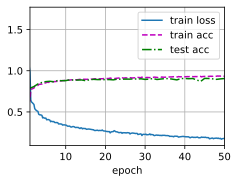

: 

In [ ]:
lr, num_epochs = 0.1, 50
train_ch6(LeNet5_improved, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

原有lenet5：
lr = 0.9, 激活函数：sigmoid，平均池化，初始化：xavier_uniform，num_epochs:10
## 训练轮数微调
在原lenet5的基础上，将num_epochs从10改成20再改成30再改成50，test acc从0.802提升到0.830又提升到0.874提升到0.884

但是再提升轮数，发现精确度曲线发生轻微震荡，而且收益不大，几乎很难再有提升

## 激活函数和参数初始化
将sigmoid层改为relu层，同时把xavier_uniform改为kaiming_uniform，训练轮数还是10，lr = 0.1

相比于最初lenet5，test acc从0.802提升到0.869

然后继续调num_epochs到30，发现涨到了0.890，再调高num_epochs提升微弱

## lr微调
在上述调整的基础上，我对lr = 0.1 进行了调整，调到了0.15，但效果并不好，经常出现轻微震荡，训练了30轮达到了0.880
## 增加dropout
分别在两个全连接和relu后面加了一个dropout(0.3, 0.5)，暂退概率分别是0.3和0.5，训练了60轮，达到0.898，而且加了暂退之后，train acc和test acc几乎一直是重合的。
训练了100轮，达到0.904，增长较为缓慢，不过总算超过了0.9
## 池化层
Avg->Max,同时dropout微调成（0.3，0.3）变成0.901
## 改变通道数
（1，6），（6， 16）改成（1，8），（8，32）0.901，感觉有点过拟合

把dropout(0.3, 0.3)改成（0.3， 0.4）后变成了0.912